# Pré-processamento — PNS 2019

## 1. Introdução e objetivo do pré-processamento

Esta etapa organiza alternativas de preparação das dez características socioeconômicas e demográficas para classificação de `ativo_lazer` por kNN. Utiliza-se a base final da extração, em continuidade à análise exploratória.

Os diagnósticos descritivos abrangem a base tratada. As transformações destinadas ao modelo permanecem no pipeline e são ajustadas exclusivamente nos dados de treinamento de cada partição. A grade contém configurações candidatas, cuja verificação funcional não constitui uma comparação completa de desempenho.

## 2. Carregamento e verificação dos dados

Confere-se o arquivo intermediário, a dimensão documentada e a validade do alvo. A extração e a limpeza inicial não são reexecutadas.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
caminho_base = ROOT / "data/interim/pns_base_eda.parquet"
if not caminho_base.is_file():
    raise FileNotFoundError(
        "Execute na raiz ou em notebooks; base intermediária ausente."
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessamento import (
    ALVO,
    CATEGORICAS,
    NUMERICAS,
    construir_pipeline,
    configuracoes_experimentais,
    separar_xy,
    validacao_cruzada,
)

df = pd.read_parquet(caminho_base)
print("Dimensões:", df.shape)
assert df.shape == (
    88456,
    11,
), "Divergência com README: investigar antes de prosseguir"
assert df[ALVO].isin([0, 1]).all()
display(
    df[ALVO]
    .value_counts(dropna=False)
    .rename_axis("ativo_lazer")
    .to_frame("registros")
)


Dimensões: (88456, 11)


,registros
ativo_lazer,
0,63391
1,25065


O alvo distingue atividade insuficiente (0) e suficiente (1). As frequências apresentadas descrevem a amostra tratada, sem ponderação amostral.

## 3. Características selecionadas

São preservadas três características numéricas e sete categóricas. Perguntas sobre exercício e tempos derivados usados na construção do alvo ficam excluídos dos preditores, evitando vazamento direto de informação.

In [2]:
display(
    pd.DataFrame(
        {
            "característica": NUMERICAS + CATEGORICAS,
            "natureza": ["Numérica"] * len(NUMERICAS)
            + ["Categórica"] * len(CATEGORICAS),
        }
    )
)


,característica,natureza
0,idade,Numérica
1,renda_per_capita,Numérica
2,numero_moradores,Numérica
3,sexo,Categórica
4,escolaridade,Categórica
5,uf,Categórica
6,situacao_trabalho,Categórica
7,area_residencia,Categórica
8,raca_cor,Categórica
9,estado_civil,Categórica


## 4. Diagnóstico dos valores ausentes

Verificam-se tipos e ausências antes das transformações. A base documentada está completa; renda zero representa um valor observado, não uma ausência.

In [3]:
display(
    pd.DataFrame({"tipo": df.dtypes.astype(str), "ausentes": df.isna().sum()})
)
assert not df.isna().any().any(), "Base diverge da extração documentada"


,tipo,ausentes
idade,int64,0
sexo,str,0
escolaridade,str,0
renda_per_capita,int64,0
uf,str,0
situacao_trabalho,str,0
area_residencia,str,0
raca_cor,str,0
estado_civil,str,0
numero_moradores,int64,0


A verificação de completude refere-se à base atual. Os imputadores são mantidos como proteção para lacunas futuras e são ajustados apenas no treino. O alvo nunca é imputado.

## 5. Análise de quartis, IQR e outliers

Q1 e Q3 delimitam os 50% centrais. O intervalo interquartil é IQR = Q3 − Q1. Valores fora de Q1 − 1,5 IQR e Q3 + 1,5 IQR são sinalizados para diagnóstico; esse critério não comprova erro nem determina exclusão.

In [4]:
quartis = df[NUMERICAS].quantile([0.25, 0.5, 0.75]).T
quartis.columns = ["Q1", "mediana", "Q3"]
quartis["IQR"] = quartis["Q3"] - quartis["Q1"]
quartis["inferior"] = quartis["Q1"] - 1.5 * quartis["IQR"]
quartis["superior"] = quartis["Q3"] + 1.5 * quartis["IQR"]
quartis["extremos"] = [
    int(
        (
            (df[coluna] < quartis.loc[coluna, "inferior"])
            | (df[coluna] > quartis.loc[coluna, "superior"])
        ).sum()
    )
    for coluna in NUMERICAS
]
quartis["percentual_extremos"] = 100 * quartis["extremos"] / len(df)
display(quartis)


,Q1,mediana,Q3,IQR,inferior,superior,extremos,percentual_extremos
idade,33.0,46.0,60.0,27.0,-7.5,100.5,18,0.020349
renda_per_capita,499.0,998.0,1667.0,1168.0,-1253.0,3419.0,8397,9.492855
numero_moradores,2.0,3.0,4.0,2.0,-1.0,7.0,807,0.912318


As sinalizações podem se sobrepor entre características e não devem ser somadas como pessoas distintas. Mantém-se a decisão da EDA de preservar extremos socioeconômicos potencialmente legítimos. A exclusão anterior de 48 durações superiores a seis horas diárias ocorreu na extração, antes do filtro de adultos, e não é reaplicada.

## 6. Boxplots e interpretação dos resultados

Os boxplots apresentam quartis, mediana e extremos nas unidades originais. Os bigodes alcançam observações dentro dos limites de 1,5 IQR; suas pontas não precisam coincidir com os limites teóricos.

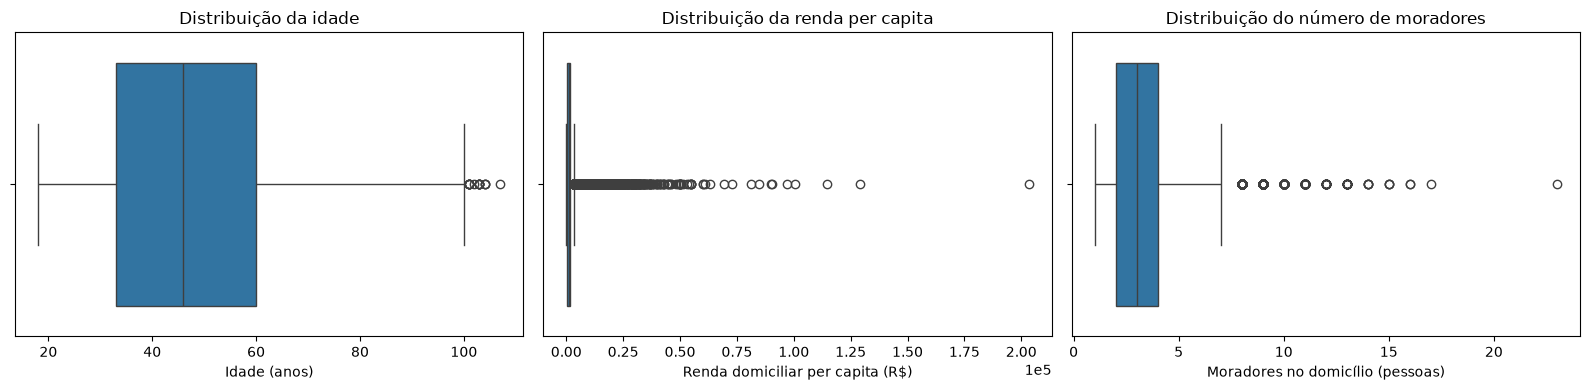

In [5]:
rotulos = {
    "idade": ("Distribuição da idade", "Idade (anos)"),
    "renda_per_capita": (
        "Distribuição da renda per capita",
        "Renda domiciliar per capita (R$)",
    ),
    "numero_moradores": (
        "Distribuição do número de moradores",
        "Moradores no domicílio (pessoas)",
    ),
}
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
for eixo, coluna in zip(eixos, NUMERICAS):
    sns.boxplot(data=df, x=coluna, ax=eixo, showfliers=True)
    titulo, unidade = rotulos[coluna]
    eixo.set(title=titulo, xlabel=unidade, ylabel="")
eixos[1].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
fig.tight_layout()
plt.show()


A idade apresenta poucos valores além dos bigodes, enquanto domicílios numerosos formam uma cauda superior. Na renda, valores elevados comprimem a região central na escala original. Esses pontos podem expressar heterogeneidade social e não são removidos automaticamente.

Para examinar melhor a renda, utiliza-se também `log1p`, equivalente a ln(1 + renda). A transformação aceita renda zero e comprime a cauda superior. Trata-se de visualização adicional, sem substituir a coluna original.

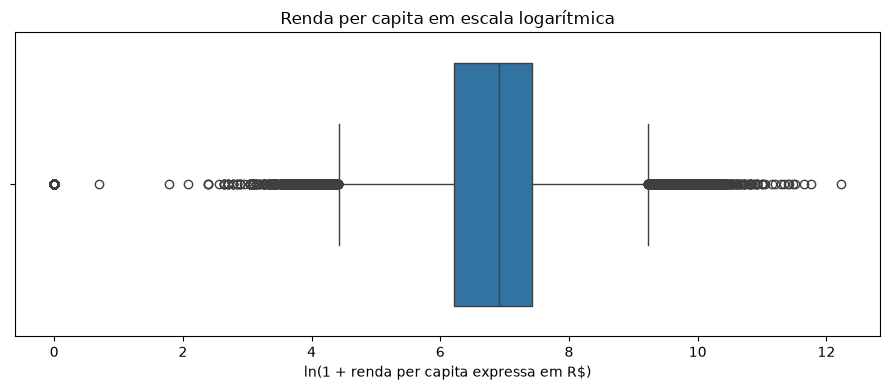

In [6]:
fig, eixo = plt.subplots(figsize=(9, 4))
sns.boxplot(x=np.log1p(df["renda_per_capita"]), ax=eixo, showfliers=True)
eixo.set(
    title="Renda per capita em escala logarítmica",
    xlabel="ln(1 + renda per capita expressa em R$)",
    ylabel="",
)
fig.tight_layout()
plt.show()


A escala logarítmica torna a dispersão central mais visível e preserva a ordenação das rendas. Os pontos além dos bigodes nessa escala seguem outro critério de distância; sua contagem não equivale à obtida pelo IQR da renda original.

## 7. Preparação de variáveis numéricas e categóricas

`separar_xy` retorna cópias dos dez preditores e do alvo. As numéricas são convertidas para ponto flutuante, e as categorias são uniformizadas como texto, preservando ausências. Valores numéricos infinitos e alvos incompletos ou diferentes de 0/1 são rejeitados.

In [7]:
X, y = separar_xy(df)
assert list(X.columns) == NUMERICAS + CATEGORICAS
assert ALVO not in X
print("Preditores:", X.shape, "| Alvo:", y.shape)


Preditores: (88456, 10) | Alvo: (88456,)


## 8. Estratégias de encoding

One-Hot Encoding representa as sete características categóricas por indicadores, incluindo UF e escolaridade. A estratégia evita impor distâncias ordinais artificiais. Categorias desconhecidas na validação geram indicadores zero no respectivo bloco.

A imputação categórica utiliza a moda do treino. Nas numéricas, média e mediana estão disponíveis; a grade fixa mediana, pois ambas coincidem operacionalmente quando não há ausências.

## 9. Normalização e padronização

StandardScaler centraliza pela média e divide pelo desvio padrão do treino. MinMaxScaler utiliza os extremos do treino; valores futuros podem ultrapassar [0, 1]. RobustScaler utiliza mediana e IQR, reduzindo a influência dos extremos na escala, sem eliminá-los.

Os escalonadores atuam nas três numéricas. Os indicadores categóricos permanecem binários. Essa escolha altera o peso relativo das características nas distâncias do kNN e deve ser avaliada experimentalmente.

## 10. Tratamento de extremos e discretização

São preservadas três alternativas: manutenção dos valores, transformação `log1p` apenas da renda e limitação das numéricas aos limites de 1,5 IQR aprendidos no treino. Nenhuma remove linhas; a limitação pode suprimir diferenças sociais legítimas.

A discretização por três ou cinco quantis gera indicadores one-hot e substitui escala e tratamento de extremos. Empates podem reduzir a quantidade efetiva de faixas. Os limites também são ajustados apenas no treino.

## 11. Seleção de atributos e PCA

SelectPercentile utiliza `f_classif` para reter 25%, 40%, 50%, 60%, 75% ou 90% das colunas codificadas; 100% desativa essa etapa. A seleção incide sobre os indicadores resultantes, não diretamente sobre as dez características originais.

PCA é opcional, com limiares de 80%, 90%, 95% ou 99% da variância. Utiliza SVD completo em matriz densa centrada, após a seleção. Ambas as etapas ficam no pipeline. A saída densa facilita PCA, mas demanda atenção à memória.

## 12. Organização das configurações experimentais

A grade combina nove bases contínuas (três escalas × três tratamentos de extremos) e duas discretizadas, sete opções de seleção e cinco de PCA: **11 × 7 × 5 = 385 configurações candidatas**.

Esse total não representa 385 experimentos completos nem garante transformações distintas. Seleção e limiares de PCA podem produzir representações equivalentes. A auditoria funcional registra equivalências em uma amostra fixa, sem comprovar equivalência para toda a base ou todas as partições.

In [8]:
receitas = configuracoes_experimentais()
assert len(receitas) == 385
print("Configurações candidatas:", len(receitas))
display(pd.DataFrame(receitas).head())


Configurações candidatas: 385


,imputacao,escala,extremos,selecao,pca,faixas
0,median,standard,preservar,25,NaN,NaN
1,median,standard,preservar,25,0.80,NaN
2,median,standard,preservar,25,0.90,NaN
3,median,standard,preservar,25,0.95,NaN
4,median,standard,preservar,25,0.99,NaN


## 13. Testes funcionais e integração com kNN

A amostra estratificada de 240 registros de treino e 60 de validação permite verificar todas as preparações, sem realizar comparação de métricas entre receitas. Confere-se saída numérica e finita, dimensão consistente e manutenção de todos os parâmetros padrão do kNN.

In [9]:
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X,
    y,
    train_size=240,
    test_size=60,
    stratify=y,
    random_state=42,
)
for receita in receitas:
    modelo = construir_pipeline(**receita)
    preparacao = modelo[:-1]
    treino = preparacao.fit_transform(X_treino, y_treino)
    validacao = preparacao.transform(X_validacao)
    assert np.isfinite(treino).all() and np.isfinite(validacao).all()
    assert np.issubdtype(treino.dtype, np.number)
    assert np.issubdtype(validacao.dtype, np.number)
    assert treino.shape[1] == validacao.shape[1]
    assert (
        modelo.named_steps["knn"].get_params()
        == KNeighborsClassifier().get_params()
    )

modelo = construir_pipeline()
modelo.fit(X_treino, y_treino)
assert modelo.predict(X_validacao).shape == (60,)
assert validacao_cruzada().get_n_splits() == 10
print(
    "385 preparações verificadas em 240/60 registros reais; um kNN padrão ajustado."
)


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consi

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consi

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


...

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


385 preparações verificadas em 240/60 registros reais; um kNN padrão ajustado.


Essas verificações avaliam funcionamento, sem estimar desempenho final. O script `tests/verificar_preprocessamento.py` também verifica imputação, escalas, extremos, categorias novas e estatísticas de treino em validação cruzada estratificada com dez partes.

O exemplo de avaliação e as orientações de integração encontram-se em [guia de pré-processamento](../docs/guia_preprocessamento.md). O pipeline completo deve ser fornecido à validação cruzada, com dados ainda não transformados.

## 14. Considerações finais e limitações

O pré-processamento preserva os dez preditores, o alvo e as alternativas metodológicas previstas. Os diagnósticos não justificam, por si, exclusão de extremos ou escolha de uma receita superior.

A comparação completa de desempenho permanece uma etapa experimental posterior. A seleção da melhor receita nas mesmas partições usadas para relatar desempenho pode produzir otimismo; a estimativa final requer teste reservado ou avaliação externa. F1 considera a classe positiva 1, e a matriz de confusão exige previsões fora da amostra.

Balanceamento permanece pendente de decisão da equipe e, se adotado, deve se restringir ao treino. Configurações equivalentes precisam ser consideradas ao interpretar a diversidade experimental. As análises não utilizam pesos amostrais, descrevem a amostra tratada e não estabelecem causalidade.